# Chapter 2: Feature Scaling

> **Data** wine_types.csv  (exercises use clinic_labs.csv) · **Time** 45 min · **Needs first** C1, and the idea of a train/test split

## What you will be able to do

1. Say which of StandardScaler, MinMaxScaler and RobustScaler suits a given column, and why
2. Fit a scaler on the training set and transform both sets without leaking
3. Show the effect of scaling on a distance-based model and on a tree
4. Recognise when a heavy tail makes StandardScaler the wrong choice
5. Apply a log transform and say what it does to a skewed column

## The one idea to hold on to

Any model that measures distance or penalises coefficients is really measuring units. Scaling decides which columns get a vote.

Welcome to Chapter 2 of Data Preprocessing. In this notebook, we will focus on **Scaling** and **Normalization** techniques.

**Why do we need to Scale Data?**

Many machine learning algorithms calculate the distance between data points. If one feature has a range of 0 to 10,000 and another has a range of 0 to 1, the model will be biased towards the larger feature. Scaling solves this by bringing all features to a similar range.

In [28]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set display options
pd.set_option('display.max_columns', None)
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Loading and Inspecting Data

We will use the `wine_types.csv` dataset, which contains chemical analysis of wines. This is a classic dataset where features have very different scales.

In [29]:
# Load the dataset
df = pd.read_csv('../../00-data/wine_types.csv')

# Display the first few rows
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (178, 14)


,Type,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


### Visualizing the Scale Difference

Let's look at two specific columns: `Proline` (which looks large, ~1000) and `Total phenols` (which looks small, ~2).

In [30]:
# Compare the statistics
df[['Proline', 'Total phenols']].describe()

,Proline,Total phenols
count,178.000000,178.000000
mean,746.893258,2.295112
std,314.907474,0.625851
min,278.000000,0.980000
25%,500.500000,1.742500
50%,673.500000,2.355000
75%,985.000000,2.800000
max,1680.000000,3.880000


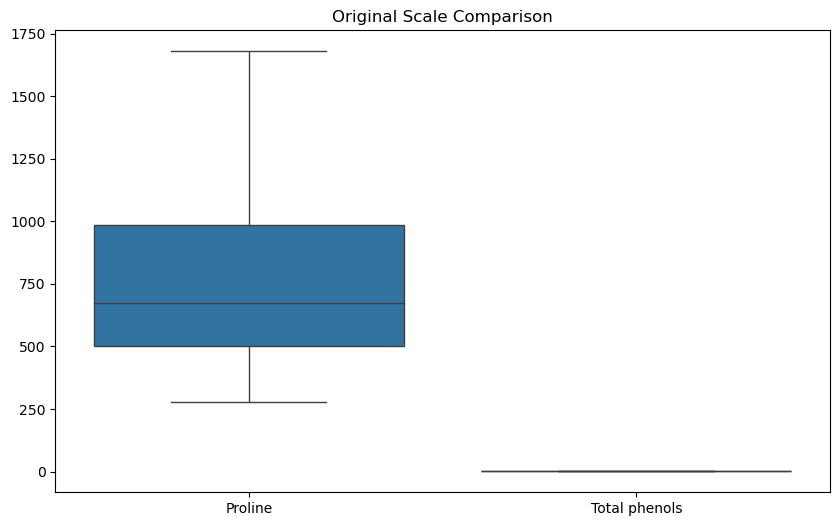

In [31]:
# Visualize with a boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[['Proline', 'Total phenols']])
plt.title("Original Scale Comparison")
plt.show()

**Observation:** `Proline` completely dwarfs `Total phenols`. Any distance-based model would essentially ignore `Total phenols`.

---

## 2. Scaling Methods Overview

| Method | Formula | Range | Best For | Handles Outliers |
|--------|---------|-------|----------|------------------|
| **StandardScaler** | (x - mean) / std | ~(-3, +3) | Gaussian data, most ML algorithms | No |
| **MinMaxScaler** | (x - min) / (max - min) | [0, 1] | Neural networks, image data | No |
| **RobustScaler** | (x - median) / IQR | Varies | Data with outliers | Yes |
| **Log Transform** | log(x) | Varies | Right-skewed data | Reduces impact |

![Scaling Comparison](https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Fwww.someka.net%2Fwp-content%2Fuploads%2F2020%2F08%2Fdifference-between-normalization-standardization-1.png)

---

## 3. Standardization (Z-Score Scaling)

Standardization transforms data so it has a **mean of 0** and a **standard deviation of 1**.

$$z = \frac{x - \mu}{\sigma}$$

Where:
- $x$ is the original value
- $\mu$ is the mean
- $\sigma$ is the standard deviation

**When to use:**
- When your data follows a Gaussian (Bell curve) distribution
- For algorithms like SVMs, Linear Regression, Logistic Regression
- When you don't need a specific range

In [5]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Select columns to scale
cols_to_scale = ['Proline', 'Total phenols']

# Apply the scaler
df_standardized = df.copy()
df_standardized[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

# Check the new statistics (Mean should be ~0, Std ~1)
print("After Standardization:")
df_standardized[cols_to_scale].describe().round(2)

After Standardization:


,Proline,Total phenols
count,178.00,178.00
mean,-0.00,0.00
std,1.00,1.00
min,-1.49,-2.11
25%,-0.78,-0.89
50%,-0.23,0.10
75%,0.76,0.81
max,2.97,2.54


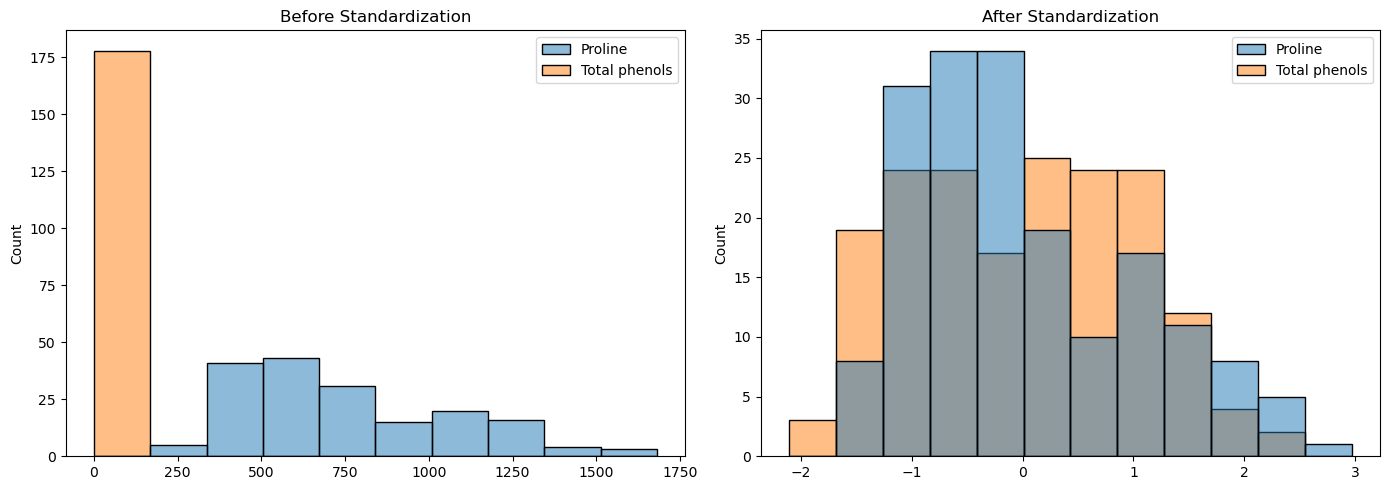

In [21]:
# Visualize the Result
fig, ax = plt.subplots( 1, 2, figsize=(14, 5))

sns.histplot(data=df[cols_to_scale], ax=ax[0])
ax[0].set_title("Before Standardization")

sns.histplot(data=df_standardized[cols_to_scale], ax=ax[1])
ax[1].set_title("After Standardization")

plt.tight_layout()
plt.show()

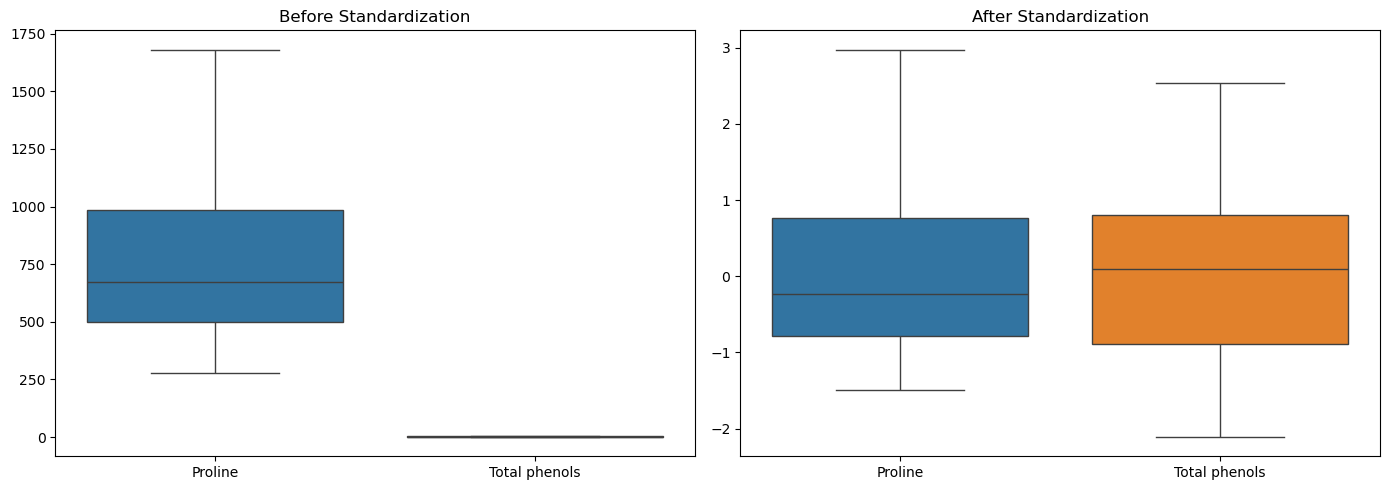

In [20]:
# Visualize the Result
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df[cols_to_scale], ax=ax[0])
ax[0].set_title("Before Standardization")

sns.boxplot(data=df_standardized[cols_to_scale], ax=ax[1])
ax[1].set_title("After Standardization")

plt.tight_layout()
plt.show()

---

## 4. Normalization (Min-Max Scaling)

Normalization scales data to a fixed range, usually **[0, 1]**.

$$x_{norm} = \frac{x - x_{min}}{x_{max} - x_{min}}$$

**When to use:**
- When data is NOT normally distributed
- Neural Networks (often converge faster with [0,1] data)
- Image processing (pixel intensities 0-255 -> 0-1)
- When you need a bounded range

In [22]:
from sklearn.preprocessing import MinMaxScaler

# Create the scaler
mm_scaler = MinMaxScaler()

# Apply scaling
df_normalized = df.copy()
df_normalized[cols_to_scale] = mm_scaler.fit_transform(df[cols_to_scale])

# Check statistics (Min should be 0, Max should be 1)
print("After Min-Max Scaling:")
df_normalized[cols_to_scale].describe()

After Min-Max Scaling:


,Proline,Total phenols
count,178.000000,178.000000
mean,0.334446,0.453487
std,0.224613,0.215811
min,0.000000,0.000000
25%,0.158702,0.262931
50%,0.282097,0.474138
75%,0.504280,0.627586
max,1.000000,1.000000


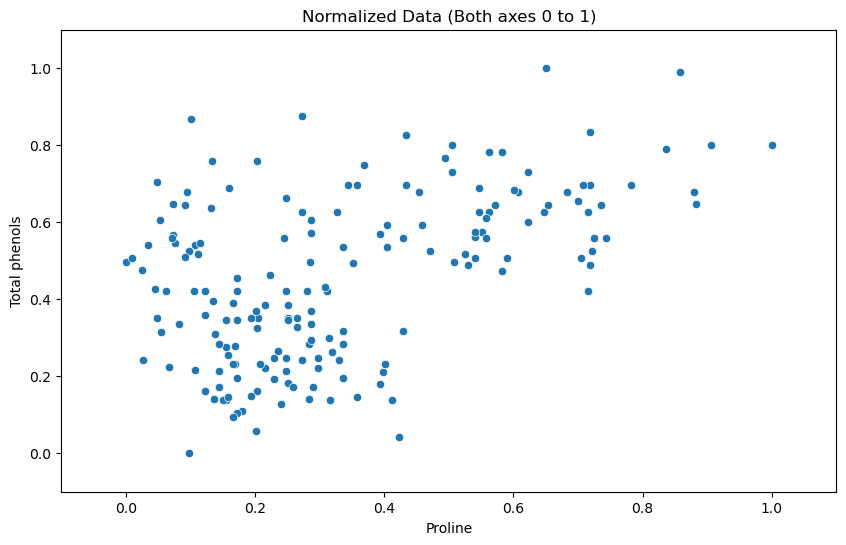

In [23]:
# Visualize comparison
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Proline', y='Total phenols', data=df_normalized)
plt.title("Normalized Data (Both axes 0 to 1)")
plt.xlim(-0.1, 1.1)
plt.ylim(-0.1, 1.1)
plt.show()

---

## 5. RobustScaler (For Data with Outliers)

**RobustScaler** uses the **median** and **interquartile range (IQR)** instead of mean and standard deviation. This makes it robust to outliers.

$$x_{robust} = \frac{x - median}{IQR}$$

Where IQR = Q3 - Q1 (75th percentile - 25th percentile)

**When to use:**
- When your data contains many outliers
- When you cannot remove outliers but need scaling
- When mean/std would be misleading

In [24]:
from sklearn.preprocessing import RobustScaler

# Create sample data with outliers
np.random.seed(42)
data_with_outliers = np.random.normal(100, 20, 100)
# Add some extreme outliers
data_with_outliers = np.append(data_with_outliers, [500, 600, -100, -200])

sample_df = pd.DataFrame({'value': data_with_outliers})

print(f"Original data stats:")
print(f"  Mean: {sample_df['value'].mean():.2f}")
print(f"  Std: {sample_df['value'].std():.2f}")
print(f"  Median: {sample_df['value'].median():.2f}")
print(f"  Min: {sample_df['value'].min():.2f}, Max: {sample_df['value'].max():.2f}")

Original data stats:
  Mean: 101.85
  Std: 74.57
  Median: 97.46
  Min: -200.00, Max: 600.00


In [25]:
# Compare all three scalers on data with outliers
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
robust_scaler = RobustScaler()

sample_df['StandardScaler'] = standard_scaler.fit_transform(sample_df[['value']])
sample_df['MinMaxScaler'] = minmax_scaler.fit_transform(sample_df[['value']])
sample_df['RobustScaler'] = robust_scaler.fit_transform(sample_df[['value']])

# Compare statistics
print("Comparison of Scalers (with outliers present):")
sample_df[['StandardScaler', 'MinMaxScaler', 'RobustScaler']].describe().round(3)

Comparison of Scalers (with outliers present):


,StandardScaler,MinMaxScaler,RobustScaler
count,104.000,104.000,104.000
mean,-0.000,0.377,0.197
std,1.005,0.093,3.349
min,-4.068,0.000,-13.358
25%,-0.190,0.360,-0.436
50%,-0.059,0.372,0.000
75%,0.110,0.388,0.564
max,6.713,1.000,22.568


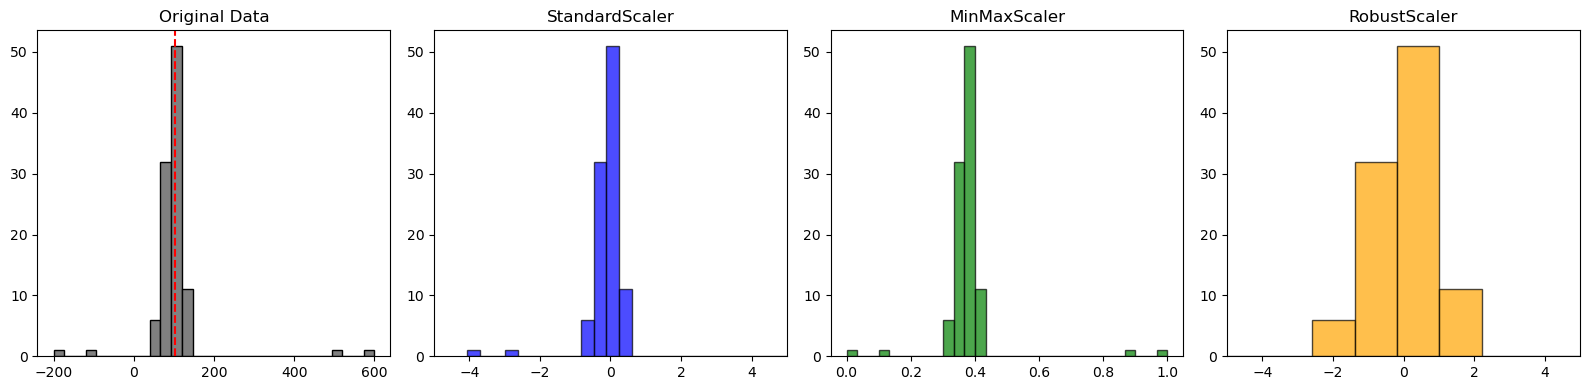


Notice: RobustScaler keeps the bulk of data centered around 0,
while outliers are less compressed than with StandardScaler.


In [26]:
# Visualize the difference
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# Original
axes[0].hist(sample_df['value'], bins=30, color='gray', edgecolor='black')
axes[0].set_title('Original Data')
axes[0].axvline(sample_df['value'].mean(), color='red', linestyle='--', label='Mean')

# StandardScaler
axes[1].hist(sample_df['StandardScaler'], bins=30, color='blue', edgecolor='black', alpha=0.7)
axes[1].set_title('StandardScaler')
axes[1].set_xlim(-5, 5)

# MinMaxScaler
axes[2].hist(sample_df['MinMaxScaler'], bins=30, color='green', edgecolor='black', alpha=0.7)
axes[2].set_title('MinMaxScaler')

# RobustScaler
axes[3].hist(sample_df['RobustScaler'], bins=30, color='orange', edgecolor='black', alpha=0.7)
axes[3].set_title('RobustScaler')
axes[3].set_xlim(-5, 5)

plt.tight_layout()
plt.show()

print("\nNotice: RobustScaler keeps the bulk of data centered around 0,")
print("while outliers are less compressed than with StandardScaler.")

---

## 6. Log Transformation

Sometimes, scaling isn't enough. If your data is highly **skewed** (a long tail), models might struggle. Log transformation can make skewed distributions more normal.

**When to use:**
- Right-skewed data (long tail on the right)
- Data spanning several orders of magnitude
- Multiplicative relationships

**Important:** Data must be positive (log of negative numbers is undefined).

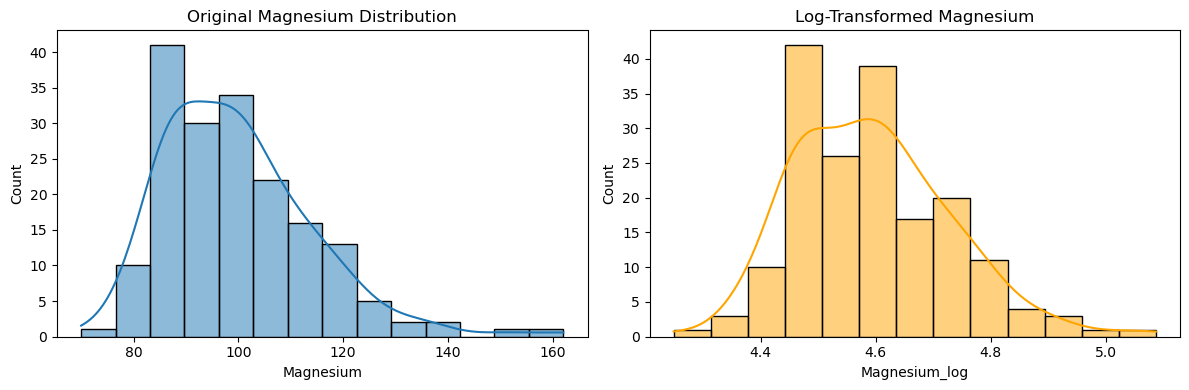

Original Variance: 203.99
Log Variance: 0.0187


In [27]:
# Check skewness of Magnesium
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(df['Magnesium'], kde=True)
plt.title("Original Magnesium Distribution")

# Apply Log Transformation
df['Magnesium_log'] = np.log(df['Magnesium'])

plt.subplot(1, 2, 2)
sns.histplot(df['Magnesium_log'], kde=True, color='orange')
plt.title("Log-Transformed Magnesium")

plt.tight_layout()
plt.show()

print(f"Original Variance: {df['Magnesium'].var():.2f}")
print(f"Log Variance: {df['Magnesium_log'].var():.4f}")

---

## 7. When NOT to Scale Your Data

**Not all algorithms require scaling!** Here's a guide:

### Algorithms that NEED Scaling:

| Algorithm | Why |
|-----------|-----|
| **K-Nearest Neighbors (KNN)** | Uses distance calculations |
| **Support Vector Machines (SVM)** | Sensitive to feature scales |
| **Linear/Logistic Regression** | Gradient descent converges faster |
| **Neural Networks** | Weight updates are more stable |
| **Principal Component Analysis (PCA)** | Variance-based, scale-dependent |
| **K-Means Clustering** | Uses distance calculations |

### Algorithms that DON'T Need Scaling:

| Algorithm | Why |
|-----------|-----|
| **Decision Trees** | Splits based on thresholds, not distances |
| **Random Forest** | Ensemble of decision trees |
| **Gradient Boosting (XGBoost, LightGBM)** | Tree-based, scale-invariant |
| **Naive Bayes** | Probability-based, not distance-based |

In [13]:
# Demonstration: Tree models don't need scaling
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Prepare data
X = df[['Proline', 'Total phenols', 'Alcohol', 'Magnesium']].values
y = df['Type'].values

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Decision Tree - doesn't need scaling
dt = DecisionTreeClassifier(random_state=42, max_depth=5)
dt_unscaled = cross_val_score(dt, X, y, cv=5).mean()
dt_scaled = cross_val_score(dt, X_scaled, y, cv=5).mean()

# KNN - needs scaling
knn = KNeighborsClassifier(n_neighbors=5)
knn_unscaled = cross_val_score(knn, X, y, cv=5).mean()
knn_scaled = cross_val_score(knn, X_scaled, y, cv=5).mean()

print("Impact of Scaling on Different Algorithms:")
print("="*50)
print(f"\nDecision Tree (doesn't need scaling):")
print(f"  Unscaled: {dt_unscaled:.4f}")
print(f"  Scaled:   {dt_scaled:.4f}")
print(f"  Difference: {abs(dt_scaled - dt_unscaled):.4f}")

print(f"\nKNN (needs scaling):")
print(f"  Unscaled: {knn_unscaled:.4f}")
print(f"  Scaled:   {knn_scaled:.4f}")
print(f"  Difference: {abs(knn_scaled - knn_unscaled):.4f}")

Impact of Scaling on Different Algorithms:

Decision Tree (doesn't need scaling):
  Unscaled: 0.8490
  Scaled:   0.8490
  Difference: 0.0000

KNN (needs scaling):
  Unscaled: 0.6856
  Scaled:   0.9051
  Difference: 0.2195


---

## 8. Choosing the Right Scaler: Decision Guide

```
                    Is your data bounded [0, 1]?
                           /         \
                         Yes          No
                          |            |
                    MinMaxScaler    Does data have outliers?
                                      /           \
                                    Yes           No
                                     |             |
                               RobustScaler   Is data normally distributed?
                                                   /          \
                                                 Yes          No
                                                  |            |
                                           StandardScaler  Consider Log/MinMax
```

---

## 9. Complete Comparison Visualization

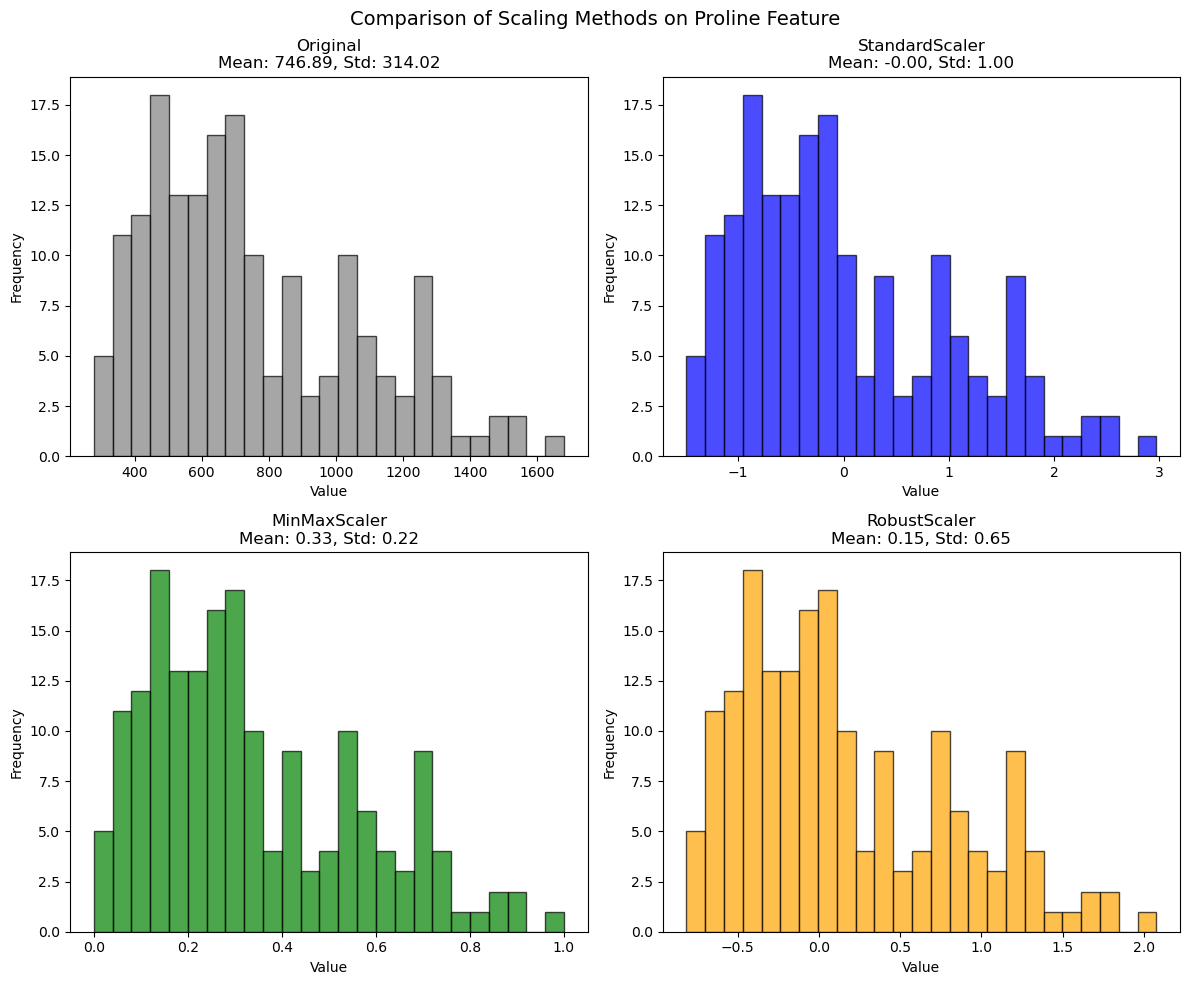

In [14]:
# Complete comparison of all scalers
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

# Use Proline column
feature = df[['Proline']].copy()

# Apply all scalers
scalers = {
    'Original': feature.values,
    'StandardScaler': StandardScaler().fit_transform(feature),
    'MinMaxScaler': MinMaxScaler().fit_transform(feature),
    'RobustScaler': RobustScaler().fit_transform(feature)
}

# Visualize
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

colors = ['gray', 'blue', 'green', 'orange']
for i, (name, data) in enumerate(scalers.items()):
    axes[i].hist(data, bins=25, color=colors[i], edgecolor='black', alpha=0.7)
    axes[i].set_title(f'{name}\nMean: {data.mean():.2f}, Std: {data.std():.2f}')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

plt.suptitle('Comparison of Scaling Methods on Proline Feature', fontsize=14)
plt.tight_layout()
plt.show()

---

## Summary

| Scaler | Use When | Advantages | Disadvantages |
|--------|----------|------------|---------------|
| **StandardScaler** | Normally distributed data | Handles negative values, good for gradient-based | Affected by outliers |
| **MinMaxScaler** | Need bounded [0,1] range | Preserves relationships, good for neural nets | Very sensitive to outliers |
| **RobustScaler** | Data has outliers | Not affected by extreme values | Range varies |
| **Log Transform** | Right-skewed data | Reduces skewness | Only for positive data |

### What's Next?

Continue to:
- **Chapter 3**: Feature Engineering - Create new features from existing data
- **Chapter 4**: Categorical Encoding - Convert text categories to numbers

---

## Exercises

### Exercise 1: Standardize 'Alcohol'

1. Create a `StandardScaler`.
2. Standardize the `Alcohol` column.
3. Verify that the mean is ~0 and std is ~1.

In [15]:
# Your code here


### Exercise 2: Compare Scalers on Color Intensity

1. Apply `StandardScaler`, `MinMaxScaler`, and `RobustScaler` to `Color intensity`.
2. Create a side-by-side histogram comparison.
3. Which scaler would you recommend and why?

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

col = df[['Color intensity']]

# 1. Apply all three scalers to the same column
scaled = {
    'Original': col.values.ravel(),
    'StandardScaler': StandardScaler().fit_transform(col).ravel(),
    'MinMaxScaler': MinMaxScaler().fit_transform(col).ravel(),
    'RobustScaler': RobustScaler().fit_transform(col).ravel(),
}

summary = pd.DataFrame(
    {name: pd.Series(v).describe()[['mean', 'std', 'min', '50%', 'max']]
     for name, v in scaled.items()}
).T
print(f"Skew of 'Color intensity': {col['Color intensity'].skew():.2f}  (right-tailed)")
print(summary.round(3))

# 2. Side-by-side histogram comparison
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, values) in zip(axes, scaled.items()):
    ax.hist(values, bins=25, color='steelblue', edgecolor='black', alpha=0.8)
    ax.set_title(f'{name}\nmean={values.mean():.2f}, std={values.std():.2f}')
    ax.set_xlabel('Value')
axes[0].set_ylabel('Frequency')
plt.suptitle("'Color intensity' under three scalers", fontsize=14)
plt.tight_layout()
plt.show()

# 3. The shape never changes - only the axis does. All three are linear maps.
print("\nSame shape, different axis: skew is identical after every scaler")
for name, values in scaled.items():
    print(f"  {name:16s} skew = {pd.Series(values).skew():.4f}")


**Answer to Exercise 2 (part 3): use `RobustScaler`.**

`Color intensity` runs from 1.28 to 13.0 with a skew of +0.87 and four wines past the
1.5 x IQR fence. That tail is what decides between the three:

| Scaler | What the tail does to it |
|--------|--------------------------|
| `StandardScaler` | Centres on the **mean**, which the tail drags upward, so the median lands at -0.16 instead of 0 and most wines sit below zero. |
| `MinMaxScaler` | The single wine at 13.0 defines the top of the range, so the typical wines are squashed into roughly the bottom third of [0, 1]. |
| `RobustScaler` | Centres on the **median** and divides by the IQR, both of which ignore the four extreme wines. The bulk lands in about [-1, 1] and the outliers simply sit outside it. |

Recommend `RobustScaler`: the statistics it uses (median, IQR) are unmoved by the four
extreme wines, so the middle 50% of the data gets a sensible spread instead of being
compressed to make room for the tail.

**One thing the histograms do not show.** All three scalers are linear maps
(`(x - a) / b`), so none of them changes the *shape* of the distribution - the skew is
+0.87 before and after every one of them, and the four bars stay in the same places. Only
the x-axis numbers move. If you actually want to pull the tail in, you need a non-linear
transform such as `np.log1p`; scaling and de-skewing are two different jobs.


### Exercise 3: Scaling Impact on Model Performance

1. Load the wine dataset and prepare features (exclude Type).
2. Train a LogisticRegression model on unscaled data.
3. Train the same model on StandardScaler-transformed data.
4. Compare the cross-validation scores.

In [ ]:
from sklearn.linear_model import LogisticRegression

# Prepare features (exclude Type and the derived Magnesium_log column)
X_all = df.drop(columns=['Type', 'Magnesium_log']).values
y_all = df['Type'].values

# Scale the data
lr_scaler = StandardScaler()
X_all_scaled = lr_scaler.fit_transform(X_all)

# Logistic Regression on unscaled vs scaled data
lr = LogisticRegression(max_iter=10000, random_state=42)
lr_unscaled = cross_val_score(lr, X_all, y_all, cv=5).mean()
lr_scaled = cross_val_score(lr, X_all_scaled, y_all, cv=5).mean()

print("Impact of Scaling on Logistic Regression:")
print("=" * 50)
print(f"  Unscaled: {lr_unscaled:.4f}")
print(f"  Scaled:   {lr_scaled:.4f}")
print(f"  Difference: {abs(lr_scaled - lr_unscaled):.4f}")

In [17]:
# Your code here


---

## How this is used in real work

Every `Pipeline` you write for logistic regression, SVM, KNN, PCA or a neural network starts with a scaler. Getting it wrong is not a crash, it is a model that quietly ranks your biggest-unit column first. `RobustScaler` is what you reach for on lab values, prices and latencies, all of which have tails.

## Where this goes next

**C3** builds new columns. Scale after you build them, not before.

## Fit on the training set only, transform both sets: no leakage

Every scaler above was fitted on the whole table. In a real project the test rows arrive later, so their mean and spread must never reach the scaler. Fit on the training rows, then transform both with the numbers learned from training alone. Fitting on everything lets test-set statistics leak into the model's preprocessing, and the test score stops being an honest estimate.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test = train_test_split(df[cols_to_scale], test_size=0.2, random_state=42)
scaler = StandardScaler().fit(X_train)            # learns mean and std from TRAIN only
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)               # same numbers applied to test: no refit
print('train means after scaling:', X_train_s.mean(axis=0).round(2)[:4])   # ~0 by construction
print('test  means after scaling:', X_test_s.mean(axis=0).round(2)[:4])    # not 0: test was never seen
# fit_transform on the whole frame would have made both rows ~0, and hidden the leak.